In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import math, time, copy
import torch
from torch import nn
from torch.nn import functional as F

In [2]:
DATA = Path("/home/beown/Pictures/DL4TSG/assignment/DL4STG-PA1/DL4STG-PA1/Question 2 - Leaderboard/Data")
train = pd.read_csv(DATA / "student_train.csv")
test  = pd.read_csv(DATA / "student_test.csv")
ext   = pd.read_csv(DATA / "optional_external_data.csv")

print("train:", train.shape, " test:", test.shape, " external:", ext.shape)
print(train.head())
print(test.head())
print(ext.head())

train: (43656, 2)  test: (168, 2)  external: (43824, 11)
   time_idx  value
0         1    129
1         2    129
2         3    129
3         4    129
4         5    129
   time_idx  value
0     43657    NaN
1     43658    NaN
2     43659    NaN
3     43660    NaN
4     43661    NaN
   time_idx  feature_A  feature_B  feature_C  feature_D  feature_E  feature_F  \
0         1        -21      -11.0     1021.0       1.79          0          0   
1         2        -21      -12.0     1020.0       4.92          0          0   
2         3        -21      -11.0     1019.0       6.71          0          0   
3         4        -21      -14.0     1019.0       9.84          0          0   
4         5        -20      -12.0     1018.0      12.97          0          0   

   feature_G  feature_H  feature_I  feature_J  
0          0          1          0          0  
1          0          1          0          0  
2          0          1          0          0  
3          0          1          0  

In [3]:
# checking missing values, gaps in time_idx
print("missing values in train:", train.isna().sum().sum())
print("time_idx steps all equal 1: ", (train["time_idx"].diff().dropna() == 1).all())
print("test range:", test["time_idx"].min(), "to", test["time_idx"].max())
print("length", len(test))

print("\n")
print(train["value"].describe(percentiles=[0.5, 0.9, 0.99]))
print("\n")

print("fraction of zeros:", (train["value"] == 0).mean())

# spliting external features into binary and continuous
feat   = [c for c in ext.columns if c != "time_idx"]
binary = [c for c in feat if set(ext[c].dropna().unique()) <= {0, 1}]
cont   = [c for c in feat if c not in binary]

print("binary features:", binary)
print("continuous features:", cont)

missing values in train: 0
time_idx steps all equal 1:  True
test range: 43657 to 43824
length 168


count    43656.000000
mean        98.173539
std         90.834754
min          0.000000
50%         73.000000
90%        218.000000
99%        418.000000
max        994.000000
Name: value, dtype: float64


fraction of zeros: 4.581271761040865e-05
binary features: ['feature_G', 'feature_H', 'feature_I', 'feature_J']
continuous features: ['feature_A', 'feature_B', 'feature_C', 'feature_D', 'feature_E', 'feature_F']


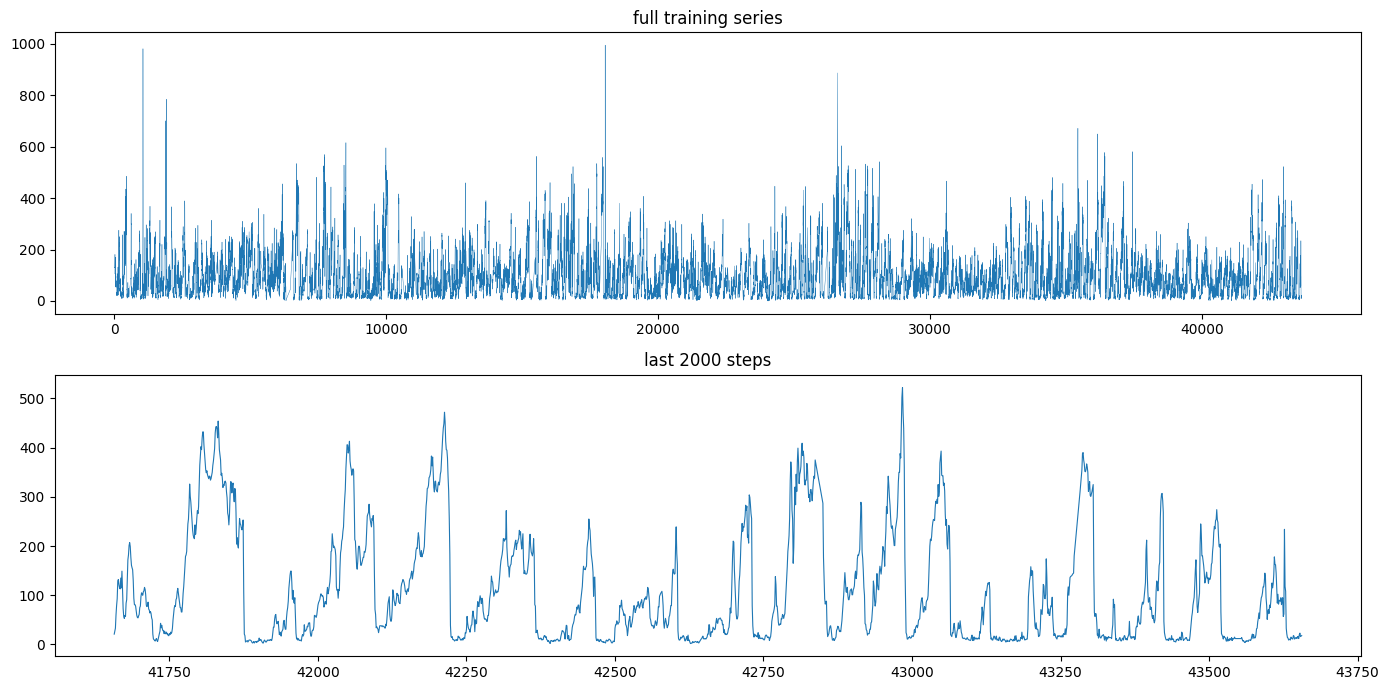

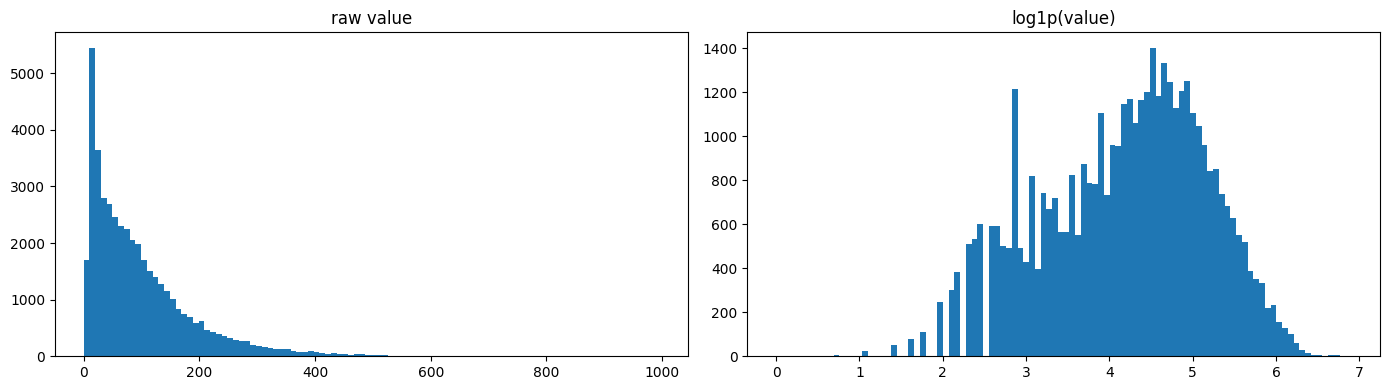

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7))
axes[0].plot(train["time_idx"], train["value"], lw=0.3)
axes[0].set_title("full training series")

last = train.tail(2000)
axes[1].plot(last["time_idx"], last["value"], lw=0.8)
axes[1].set_title("last 2000 steps")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(train["value"], bins=100); axes[0].set_title("raw value")
axes[1].hist(np.log1p(train["value"]), bins=100); axes[1].set_title("log1p(value)")
plt.tight_layout(); plt.show()

top ACF peaks: 
  192: 0.044
  216: 0.037
  312: 0.043
  337: 0.060
  359: 0.047
  505: 0.050
  528: 0.066
  720: 0.045
  745: 0.053
  767: 0.042

strongest periods in the spectrum:
[ 269.5  183.4  386.3   24.   338.4  379.6  289.1 1559.1  187.4  216.1]


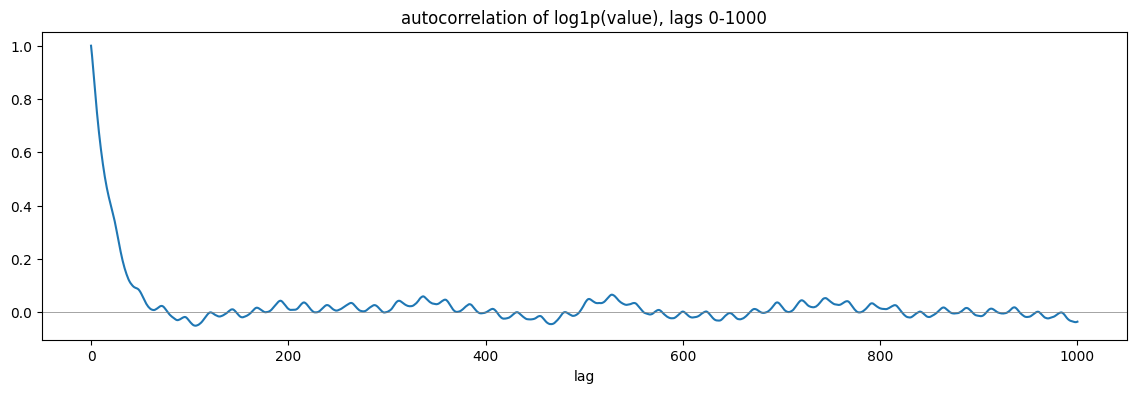

In [5]:
y = np.log1p(train["value"].values)

def acf(x, max_lag):
  x = x - x.mean()
  n = len(x)
  f = np.fft.rfft(x, n=2 * n)
  r = np.fft.irfft(f * np.conj(f))[: max_lag + 1]
  return r / r[0]

r = acf(y, 1000)

peaks = [i for i in range(5, 1000) if r[i] > r[i - 1] and r[i] > r[i + 1]] # local peaks
top = sorted(peaks, key=lambda i: r[i], reverse=True)[:10]
print("top ACF peaks: ")
for i in sorted(top):
    print(f"  {i}: {r[i]:.3f}")

power = np.abs(np.fft.rfft(y - y.mean())) ** 2 # which cycle lengths carry the most power
freqs = np.fft.rfftfreq(len(y))
periods = 1 / freqs[1:]; power = power[1:]
mask = periods < 2000
order = np.argsort(power[mask])[::-1][:10]
print("\nstrongest periods in the spectrum:")
print(np.round(periods[mask][order], 1))

plt.figure(figsize=(14, 4))
plt.plot(r); plt.axhline(0, color="grey", lw=0.5)
plt.title("autocorrelation of log1p(value), lags 0-1000"); plt.xlabel("lag")
plt.show()

In [6]:
df = train.merge(ext, on="time_idx", how="left")
df["log_value"] = np.log1p(df["value"])

corr = df[cont + ["log_value"]].corr()["log_value"].drop("log_value").sort_values()
print(f"correlation of continuous features with log1p(value): {corr.round(3)}")

mean = pd.Series({c: df.loc[df[c] == 1, "log_value"].mean() for c in binary})
print(f"\nmean log1p(value) when each binary flag is on: {mean.round(3)}")

rows = {}
for lead in [0, 1, 6, 24, 72, 168]:
  fut = df["log_value"].shift(-lead)
  rows[lead] = {c: df[c].corr(fut) for c in cont}
corr = pd.DataFrame(rows)
print(f"\ncorrelation of feature(t) with log1p(value)(t+h): {corr.round(3)}")

correlation of continuous features with log1p(value): feature_D   -0.348
feature_C   -0.159
feature_F   -0.049
feature_B    0.019
feature_E    0.032
feature_A    0.308
Name: log_value, dtype: float64

mean log1p(value) when each binary flag is on: feature_G    3.989
feature_H    3.668
feature_I    4.473
feature_J    4.515
dtype: float64

correlation of feature(t) with log1p(value)(t+h):              0      1      6      24     72     168
feature_A  0.308  0.304  0.244  0.101  0.009  0.029
feature_B  0.019  0.017  0.049  0.002 -0.009 -0.004
feature_C -0.159 -0.155 -0.129  0.023  0.025 -0.025
feature_D -0.348 -0.346 -0.301 -0.153 -0.015 -0.031
feature_E  0.032  0.033  0.035 -0.018 -0.005  0.021
feature_F -0.049 -0.057 -0.069 -0.071 -0.011 -0.019


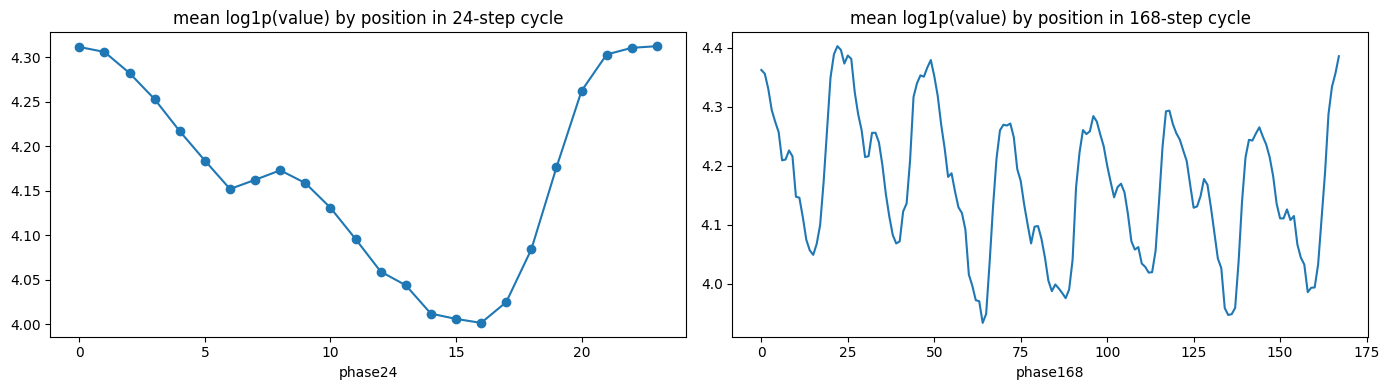

variance explained by 24-step profile: 0.011


In [7]:
df["phase24"]  = (df["time_idx"] - 1) % 24
df["phase168"] = (df["time_idx"] - 1) % 168
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df.groupby("phase24")["log_value"].mean().plot(ax=axes[0], marker="o")
axes[0].set_title("mean log1p(value) by position in 24-step cycle")
df.groupby("phase168")["log_value"].mean().plot(ax=axes[1])
axes[1].set_title("mean log1p(value) by position in 168-step cycle")
plt.tight_layout(); plt.show()

prof = df.groupby("phase24")["log_value"].transform("mean")
print("variance explained by 24-step profile:",round(1 - ((df["log_value"] - prof)**2).mean() / df["log_value"].var(), 3))

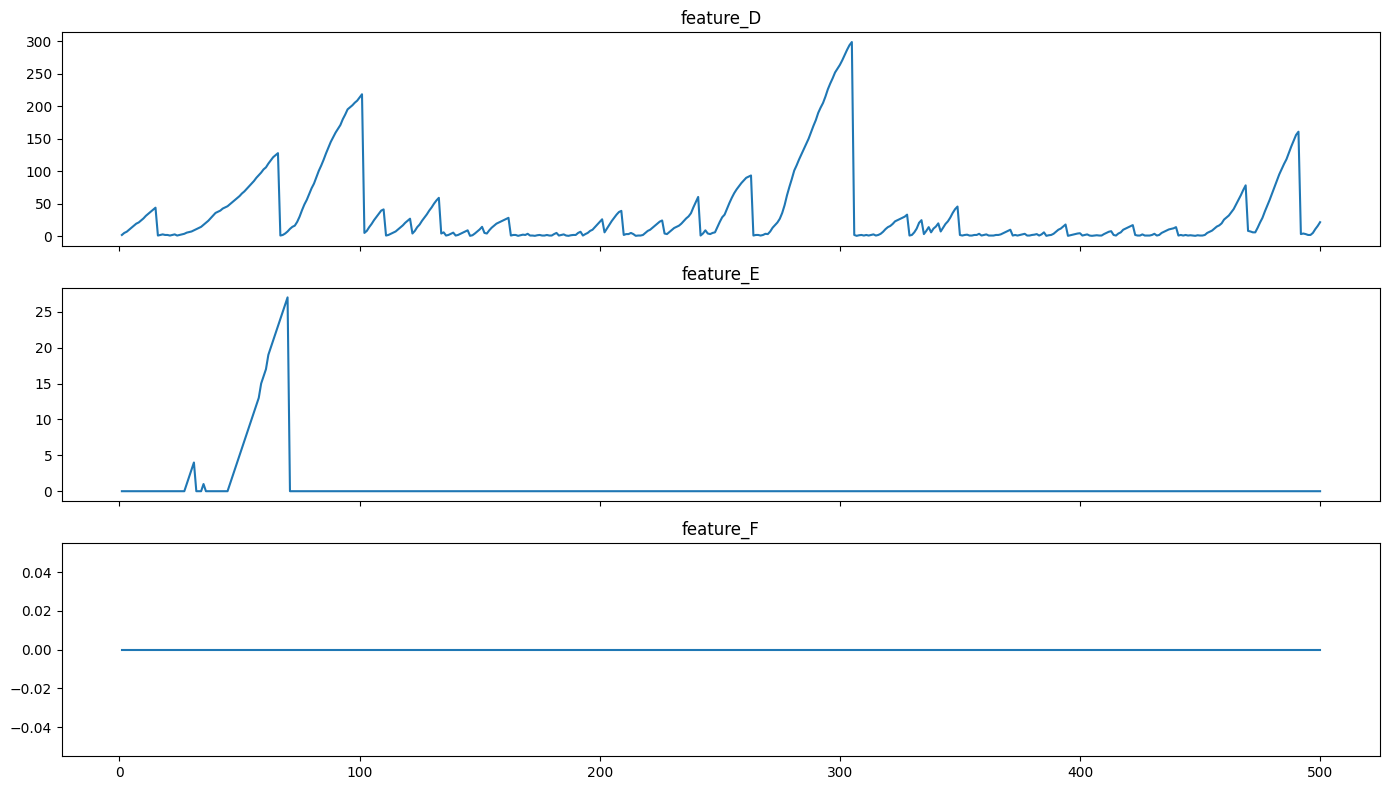

fraction of steps in a run of >= 5 identical values: 0.0036


In [8]:
fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)
seg = df.iloc[:500]
for ax, c in zip(axes, ["feature_D", "feature_E", "feature_F"]):
  ax.plot(seg["time_idx"], seg[c]); ax.set_title(c)
plt.tight_layout(); plt.show()

runs = (train["value"] != train["value"].shift()).cumsum()
run_len = train.groupby(runs)["value"].transform("size")
print("fraction of steps in a run of >= 5 identical values:", round((run_len >= 5).mean(), 4))

In [9]:
h = 168  # forecast horizon
n = 12   # number of 168-step
tt = len(train)
y_raw = train["value"].values.astype(float)

val_start  = tt - n * h
stop_start = val_start - n * h
val_origins = [val_start + k * h for k in range(n)]

print(f"train: time_idx 1 to {stop_start}")
print(f"early-stop: time_idx {stop_start + 1} to {val_start}")
print(f"validation: time_idx {val_start + 1} to {tt}  ({n} blocks of {h})")

train: time_idx 1 to 39624
early-stop: time_idx 39625 to 41640
validation: time_idx 41641 to 43656  (12 blocks of 168)


In [10]:
def metrics(y, yhat):
  y, yhat = np.asarray(y, float), np.asarray(yhat, float)
  err = y - yhat
  denom = np.abs(y) + np.abs(yhat)
  smape = np.where(denom == 0, 0.0, 2 * np.abs(err) / np.where(denom == 0, 1, denom))
  return {"MAE": np.abs(err).mean(), "RMSE": np.sqrt((err ** 2).mean()), "sMAPE": 100 * smape.mean()}

In [11]:
phase = np.arange(tt) % 24
log_y = np.log1p(y_raw)
profile24 = pd.Series(log_y[:val_start]).groupby(phase[:val_start]).mean().values

def persistence(hist, origin):
  return np.repeat(hist[-1], h)

def seasonal24(hist, origin):
  return np.tile(hist[-24:], h // 24)

def seasonal168(hist, origin):
  return hist[-168:].copy()

def recent_mean(hist, origin):
  return np.repeat(hist[-168:].mean(), h)

def profile(hist, origin):
  idx = np.arange(origin, origin + h) % 24
  return np.expm1(profile24[idx])

baselines = {"persistence": persistence, "seasonal naive (24)": seasonal24,"seasonal naive (168)": seasonal168,
             "recent mean (168)": recent_mean, "24-step profile": profile}

rows = []
for name, fn in baselines.items():
  for k, o in enumerate(val_origins):
    pred = np.clip(fn(y_raw[:o], o), 0, None)
    rows.append({"model": name, "block": k, **metrics(y_raw[o:o + h], pred)})
base_results = pd.DataFrame(rows)

summary = base_results.groupby("model")[["RMSE", "MAE", "sMAPE"]].agg(["mean", "std"]).round(2)
print(summary.sort_values(("RMSE", "mean")))

                        RMSE             MAE           sMAPE       
                        mean     std    mean     std    mean    std
model                                                              
recent mean (168)     111.64   29.01   90.62   26.10   90.93  18.79
24-step profile       113.80   40.30   84.31   28.92   92.20  14.75
seasonal naive (24)   153.21   52.43  119.64   50.37  105.25  23.03
seasonal naive (168)  157.85   35.60  121.93   33.50  108.74  17.66
persistence           173.98  106.94  142.48  109.87  104.12  24.00


In [12]:
per_block = base_results.pivot(index="block", columns="model", values="RMSE").round(1)
display(per_block)

best_block = per_block.min().idxmin()
best_by_mean = per_block.mean().idxmin()

rmse_min = per_block[best_by_mean].min()
rmse_max = per_block[best_by_mean].max()

rmse_range = {
  "min": round(rmse_min, 1),
  "max": round(rmse_max, 1),
}


print(f"best baseline by mean RMSE: {best_by_mean}, RMSE range across blocks: {per_block[best_by_mean].min()} to {per_block[best_by_mean].max()}")

model,24-step profile,persistence,recent mean (168),seasonal naive (168),seasonal naive (24)
block,,,,,
0,110.5,103.1,106.5,112.1,103.1
1,172.0,300.9,154.9,191.6,234.8
2,127.8,158.9,102.0,216.2,145.1
3,155.8,129.3,127.5,147.5,142.9
4,88.4,146.6,103.6,156.4,96.6
5,44.4,61.4,63.1,117.0,92.3
6,124.8,150.1,132.0,143.1,156.9
7,167.4,240.1,140.3,168.0,197.5
8,116.9,442.5,141.4,211.0,249.8


best baseline by mean RMSE: recent mean (168), RMSE range across blocks: 63.1 to 154.9


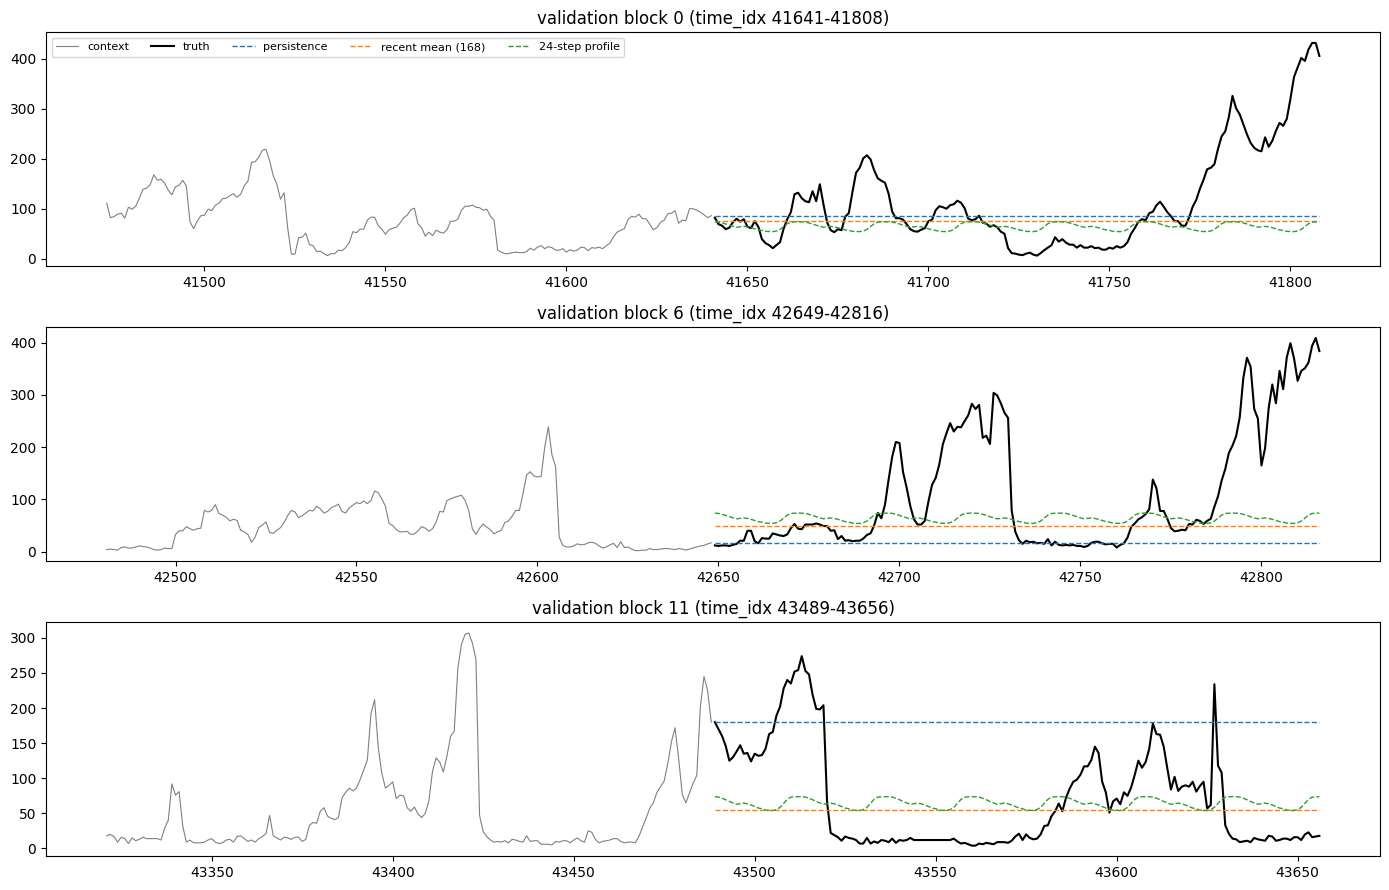

In [13]:
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=False)
for ax, k in zip(axes, [0, n // 2, n - 1]):
  o = val_origins[k]
  ttt = np.arange(o, o + h) + 1
  ax.plot(np.arange(o - 168, o) + 1, y_raw[o - 168:o], color="grey", lw=0.8, label="context")
  ax.plot(ttt, y_raw[o:o + h], color="black", lw=1.5, label="truth")
  for name in ["persistence", "recent mean (168)", "24-step profile"]:
    ax.plot(ttt, np.clip(baselines[name](y_raw[:o], o), 0, None), "--", lw=1, label=name)
  ax.set_title(f"validation block {k} (time_idx {o + 1}-{o + h})")
axes[0].legend(ncol=5, fontsize=8)
plt.tight_layout(); plt.show()

In [14]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


In [15]:
z = np.log1p(y_raw)
mu, sd = z[:stop_start].mean(), z[:stop_start].std()
Z = torch.tensor((z - mu) / sd, dtype=torch.float32, device=device)

X = ext.sort_values("time_idx").reset_index(drop=True)[cont + binary].astype(float)
for c in ["feature_D", "feature_E", "feature_F"]:
  X[c] = np.log1p(X[c].clip(lower=0))
cmu = X.loc[:stop_start - 1, cont].mean()
csd = X.loc[:stop_start - 1, cont].std().replace(0, 1)
X[cont] = (X[cont] - cmu) / csd
XC = torch.tensor(X.values, dtype=torch.float32, device=device)
n_cov = XC.shape[1]

def make_batch(origins, L):
  o = torch.as_tensor(np.asarray(origins), device=device).long()
  ctx = o[:, None] + torch.arange(-L, 0, device=device)
  fut = o[:, None] + torch.arange(0, h, device=device)
  if int(fut.max()) < len(Z):
    y = Z[fut]
  else:
    y = None
    
  return Z[ctx].unsqueeze(-1), XC[ctx], XC[fut], y

In [16]:
class SeriesDecomposition(nn.Module):
  def __init__(self, kernel):
    super().__init__(); self.kernel = kernel
  def forward(self, x):
    q = self.kernel // 2
    padded = torch.cat([x[:, :1].repeat(1, q, 1), x, x[:, -1:].repeat(1, q, 1)], dim=1)
    trend = padded.unfold(1, self.kernel, 1).mean(-1)
    return x - trend, trend

def delay_scores(queries, keys):
  queries = queries - queries.mean(-1, keepdim=True)
  keys = keys - keys.mean(-1, keepdim=True)
  spec = torch.fft.rfft(queries, dim=-1) * torch.fft.rfft(keys, dim=-1).conj()
  return torch.fft.irfft(spec, n=queries.shape[-1], dim=-1).mean((1, 2))

def aggregate_delays(values, delays, weights):
  B, h_d, f, L = values.shape; K = delays.shape[1]
  t = torch.arange(L, device=values.device)
  idx = (t.view(1, 1, L) - delays.long().view(B, K, 1)) % L
  v = values.unsqueeze(1).expand(B, K, h_d, f, L)
  idx = idx.view(B, K, 1, 1, L).expand(B, K, h_d, f, L)
  return (torch.gather(v, -1, idx) * weights.view(B, K, 1, 1, 1)).sum(1)

class AutoCorrelation(nn.Module):
  def __init__(self, d, heads, c=2.0, min_delay=1, max_delay=48):
    super().__init__()
    self.heads, self.c, self.min_delay, self.max_delay = heads, c, min_delay, max_delay
    self.query, self.key, self.value = (nn.Linear(d, d) for _ in range(3))
    self.out = nn.Linear(d, d)
    self.raw_temperature = nn.Parameter(torch.tensor(0.5413248546))
  def forward(self, x):
    B, L, d = x.shape
    shape = (B, L, self.heads, d // self.heads)
    q = self.query(x).view(shape).permute(0, 2, 3, 1)
    k = self.key(x).view(shape).permute(0, 2, 3, 1)
    v = self.value(x).view(shape).permute(0, 2, 3, 1)
    
    scores = delay_scores(q, k)
    lo, hi = self.min_delay, min(self.max_delay, L - 1)
    band = scores[:, lo:hi + 1]
    top_k = min(math.ceil(self.c * math.log(L)), band.shape[-1])
    sel, ind = band.topk(top_k, dim=-1)
    temp = F.softplus(self.raw_temperature) + 1e-6
    mixed = aggregate_delays(v, ind + lo, (sel / temp).softmax(-1))
    return self.out(mixed.permute(0, 3, 1, 2).reshape(B, L, d))

class EncoderBlock(nn.Module):
  def __init__(self, d, heads, kernel, dropout, c, max_delay):
    super().__init__()
    self.mix = AutoCorrelation(d, heads, c=c, min_delay=1, max_delay=max_delay)
    self.norm1, self.norm2 = nn.LayerNorm(d), nn.LayerNorm(d)
    self.ff = nn.Sequential(nn.Linear(d, 2 * d), nn.GELU(), nn.Dropout(dropout), nn.Linear(2 * d, d))
    self.drop = nn.Dropout(dropout)
    self.decomp1, self.decomp2 = SeriesDecomposition(kernel), SeriesDecomposition(kernel)
  def forward(self, x):
    x, _ = self.decomp1(x + self.drop(self.mix(self.norm1(x))))
    x, _ = self.decomp2(x + self.drop(self.ff(self.norm2(x))))
    return x

In [17]:
class Autoformer(nn.Module):
  def __init__(self, L, n_cov, d=16, heads=4, layers=2, kernel=25, dropout=0.1, c=2.0, past_cov=False, fut_cov=False, feat_idx=None, fut_kind="mlp"):
    super().__init__()
    self.past_cov, self.fut_cov = past_cov, fut_cov
    idx = list(range(n_cov)) if feat_idx is None else list(feat_idx)
    self.register_buffer("feat_idx", torch.tensor(idx, dtype=torch.long))
    k = len(idx)
    in_ch = 1 + (k if past_cov else 0)
    self.split = SeriesDecomposition(kernel)
    self.embed = nn.Conv1d(in_ch, d, 3, padding=1, padding_mode="circular", bias=False)
    self.position = nn.Parameter(torch.randn(1, L, d) * 0.02)
    self.blocks = nn.ModuleList([EncoderBlock(d, heads, kernel, dropout, c, max_delay=L // 2) for _ in range(layers)])
    self.norm = nn.LayerNorm(d)
    self.to_scalar = nn.Linear(d, 1)
    self.seasonal_head = nn.Linear(L, h)
    self.trend_head = nn.Linear(L, h)
    if fut_cov:
      if fut_kind == "conv": 
        self.fut_head = nn.Sequential(nn.Conv1d(k, 32, 7, padding=3, padding_mode="replicate"),nn.GELU(), nn.Conv1d(32, 1, 1))
      else:
        self.fut_head = nn.Sequential(nn.Linear(k, 16), nn.GELU(), nn.Linear(16, 1))

  def forward(self, hist, past, fut):
    past, fut = past[..., self.feat_idx], fut[..., self.feat_idx]
    x = torch.cat([hist, past], -1) if self.past_cov else hist
    seasonal, trend = self.split(x)
    enc = self.embed(seasonal.transpose(1, 2)).transpose(1, 2) + self.position
    for block in self.blocks:
      enc = block(enc)
    out = self.seasonal_head(self.to_scalar(self.norm(enc)).squeeze(-1))
    out = out + self.trend_head(trend[..., 0])
    if self.fut_cov:
      out = out + self.fut_head(fut).squeeze(-1)
    return out

def n_params(model):
  return sum(p.numel() for p in model.parameters() if p.requires_grad)

In [18]:
@torch.no_grad()
def predict_raw(model, origins, L):
  model.eval()
  hist, past, fut, _ = make_batch(origins, L)
  zhat = model(hist, past, fut) * sd + mu
  return np.clip(np.expm1(zhat.cpu().numpy()), 0, None)

def rmse_on(model, origins, L):
  preds = predict_raw(model, origins, L)
  truth = np.stack([y_raw[o:o + h] for o in origins])
  return float(np.sqrt(((preds - truth) ** 2).mean()))

def loss_fn(out, y, cfg):
  if cfg.get("loss", "log") == "raw":
    pr = torch.expm1(torch.clamp(out * sd + mu, max=8.0))
    yr = torch.expm1(y * sd + mu)
    return F.mse_loss(pr, yr) / 1e4
  return F.mse_loss(out, y)


def train_model(cfg, seed):
  torch.manual_seed(seed); np.random.seed(seed); torch.cuda.manual_seed_all(seed)
  L = cfg["L"]
  model = Autoformer(L, n_cov, d=cfg["d"], heads=cfg["heads"], layers=cfg["layers"], kernel=cfg["kernel"], dropout=cfg["dropout"], c=cfg["c"],
                       past_cov=cfg["past_cov"], fut_cov=cfg["fut_cov"],feat_idx=cfg.get("feat_idx"), fut_kind=cfg.get("fut_kind", "mlp")).to(device)
  
  opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=1e-4)
  train_origins = np.arange(L, stop_start - h + 1)
  stop_origins = np.arange(stop_start, val_start - h + 1, 24)

  best, best_state, bad, epochs = float("inf"), None, 0, 0
  for ep in range(cfg["max_epochs"]):
    model.train()
    perm = np.random.permutation(train_origins)
    for i in range(0, len(perm), cfg["batch"]):
      hist, past, fut, y = make_batch(perm[i:i + cfg["batch"]], L)
      loss = loss_fn(model(hist, past, fut), y, cfg)
      opt.zero_grad(); loss.backward()
      nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()

    epochs += 1
    score = rmse_on(model, stop_origins, L)
    if score < best:
      best, bad = score, 0
      best_ep = epochs
      best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    else:
      bad += 1
      if bad >= cfg["patience"]:
        break
  model.load_state_dict(best_state)
  model.best_epoch = best_ep
  return model, epochs, best

def eval_blocks(model, L):
  preds = predict_raw(model, val_origins, L)
  rows = []
  for k, o in enumerate(val_origins):
    row = {"block": k, **metrics(y_raw[o:o + h], preds[k])}
    rows.append(row)

  return pd.DataFrame(rows)

In [19]:
base_cfg = dict(L=168, d=16, heads=4, layers=2, kernel=25, dropout=0.1, c=2.0, past_cov=False, fut_cov=False, lr=1e-3, batch=256, max_epochs=20, patience=3)

t0 = time.time()
model, E, stop_rmse = train_model(base_cfg, seed=0)
fit_s = time.time() - t0
res = eval_blocks(model, base_cfg["L"])

print(f"parameters = {n_params(model)}, epochs = {E}, fit time = {fit_s:.1f}s,")
print(f"early-stop RMSE = {stop_rmse:.1f}")
print("validation (mean ± std over 12 blocks):")
display(res[["RMSE", "MAE", "sMAPE"]].agg(["mean", "std"]).round(2))
print("best baseline: recent mean (168), RMSE 111.64 ± 29.01")

parameters = 64019, epochs = 5, fit time = 31.0s,
early-stop RMSE = 46.7
validation (mean ± std over 12 blocks):


,RMSE,MAE,sMAPE
mean,107.53,78.73,85.59
std,36.89,26.11,13.51


best baseline: recent mean (168), RMSE 111.64 ± 29.01


In [20]:
def run_config(name, cfg, seeds=(0, 1, 2)):
  rows, block_rows = [], []
  for s in seeds:
    t0 = time.time()
    model, E, _ = train_model(cfg, s)
    fit = time.time() - t0
    res = eval_blocks(model, cfg["L"])
    rows.append({"config": name, "seed": s, "RMSE": res["RMSE"].mean(), "MAE": res["MAE"].mean(), "sMAPE": res["sMAPE"].mean(),
                "P": n_params(model), "E": E, "best_ep": model.best_epoch, "fit_s": fit})
    block_rows.append(res.assign(config=name, seed=s))
    print(f"{name:24s} seed {s}: RMSE {rows[-1]['RMSE']:.2f}, E={E}, {fit:.0f}s, best_epoch= {model.best_epoch} ")
  return pd.DataFrame(rows), pd.concat(block_rows)

In [21]:
ablation = {
  "no external": dict(past_cov=False, fut_cov=False),
  "past external": dict(past_cov=True,  fut_cov=False),
  "future external": dict(past_cov=False, fut_cov=True),
  "past + future external": dict(past_cov=True,  fut_cov=True),
}

all_runs = []
all_blocks= []
for name, opts in ablation.items():
  r, b = run_config(name, {**base_cfg, **opts})
  all_runs.append(r); all_blocks.append(b)
runs = pd.concat(all_runs, ignore_index=True)
blocks = pd.concat(all_blocks, ignore_index=True)

print("\nmean ± std across 3 seeds (each value = mean over 12 validation blocks):")
display(runs.groupby("config")[["RMSE", "MAE", "sMAPE", "P", "E", "fit_s"]].agg(["mean", "std"]).round(2).sort_values(("RMSE", "mean")))

no external              seed 0: RMSE 107.53, E=5, 27s, best_epoch= 2 
no external              seed 1: RMSE 106.68, E=4, 21s, best_epoch= 1 
no external              seed 2: RMSE 107.45, E=4, 20s, best_epoch= 1 
past external            seed 0: RMSE 107.89, E=5, 28s, best_epoch= 2 
past external            seed 1: RMSE 106.57, E=4, 22s, best_epoch= 1 
past external            seed 2: RMSE 106.41, E=4, 22s, best_epoch= 1 
future external          seed 0: RMSE 83.58, E=7, 36s, best_epoch= 4 
future external          seed 1: RMSE 80.65, E=9, 46s, best_epoch= 6 
future external          seed 2: RMSE 80.19, E=5, 25s, best_epoch= 2 
past + future external   seed 0: RMSE 73.02, E=7, 36s, best_epoch= 4 
past + future external   seed 1: RMSE 78.13, E=5, 25s, best_epoch= 2 
past + future external   seed 2: RMSE 88.84, E=4, 20s, best_epoch= 1 

mean ± std across 3 seeds (each value = mean over 12 validation blocks):


RMSE          MAE        sMAPE              P       \
                          mean   std   mean   std   mean   std     mean  std   
config                                                                         
past + future external   79.99  8.07  54.13  5.47  56.86  6.45  64692.0  0.0   
future external          81.47  1.84  54.51  1.31  55.89  1.09  64212.0  0.0   
past external           106.96  0.81  78.27  0.70  85.10  0.64  64499.0  0.0   
no external             107.22  0.47  78.22  0.46  85.05  0.48  64019.0  0.0   

                           E        fit_s         
                        mean   std   mean    std  
config                                            
past + future external  5.33  1.53  27.03   7.92  
future external         7.00  2.00  35.57  10.40  
past external           4.33  0.58  23.62   3.41  
no external             4.33  0.58  22.53   3.89

In [22]:
ref_col = [c for c in per_block.columns if "recent mean" in c.lower()][0]
ref = per_block[ref_col].values

blk = blocks.groupby(["config", "block"])["RMSE"].mean().unstack(0)
diff = blk.sub(ref, axis=0)

mean_rmse = blk.mean().round(2)
mean_diff = diff.mean().round(2)
blocks_better = (diff < 0).sum()

summary = pd.DataFrame({ 
  "mean RMSE": mean_rmse, 
  "mean diff vs recent mean": mean_diff, 
  "blocks better (of 12)": blocks_better,
}).sort_values("mean RMSE")

print(summary)

                        mean RMSE  mean diff vs recent mean  \
config                                                        
past + future external      79.99                    -31.66   
future external             81.47                    -30.19   
past external              106.96                     -4.70   
no external                107.22                     -4.44   

                        blocks better (of 12)  
config                                         
past + future external                     12  
future external                            12  
past external                               7  
no external                                 7  


In [23]:
names = cont + binary 
col = {n: i for i, n in enumerate(names)}
pick = lambda *fs: [col[f"feature_{f}"] for f in fs]

fut_cfg = {**base_cfg, "past_cov": False, "fut_cov": True}
subsets = {
  "all 10": None,
  "continuous only (A-F)": pick("A", "B", "C", "D", "E", "F"),
  "binary only (G-J)": pick("G", "H", "I", "J"),
  "strong cont. (A, C, D)": pick("A", "C", "D"),
  "A, C, D + binary": pick("A", "C", "D", "G", "H", "I", "J"),
}

sub_runs, sub_blocks = [], []
for name, idx in subsets.items():
  r, b = run_config(name, {**fut_cfg, "feat_idx": idx})
  sub_runs.append(r); sub_blocks.append(b)
sub_runs = pd.concat(sub_runs, ignore_index=True)
sub_blocks = pd.concat(sub_blocks, ignore_index=True)

metric_cols = ["RMSE", "MAE", "sMAPE", "P", "E"]

grouped = sub_runs.groupby("config")[metric_cols]
agg = grouped.agg(["mean", "std"])
agg = agg.round(2)
agg = agg.sort_values(("RMSE", "mean"))

print(agg)

sblk = sub_blocks.groupby(["config", "block"])["RMSE"].mean().unstack(0)
sdiff = sblk.sub(sblk["all 10"], axis=0)

mean_rmse = sblk.mean().round(2)
mean_diff = sdiff.mean().round(2)
blocks_better = (sdiff < 0).sum()

summary = pd.DataFrame({
  "mean RMSE": mean_rmse,
  "diff vs all 10": mean_diff,
  "blocks better than all 10": blocks_better,
}).sort_values("mean RMSE")

print(summary)

all 10                   seed 0: RMSE 83.39, E=7, 35s, best_epoch= 4 
all 10                   seed 1: RMSE 78.59, E=9, 45s, best_epoch= 6 
all 10                   seed 2: RMSE 80.29, E=5, 25s, best_epoch= 2 
continuous only (A-F)    seed 0: RMSE 80.95, E=6, 30s, best_epoch= 3 
continuous only (A-F)    seed 1: RMSE 81.15, E=5, 25s, best_epoch= 2 
continuous only (A-F)    seed 2: RMSE 78.82, E=9, 47s, best_epoch= 6 
binary only (G-J)        seed 0: RMSE 102.29, E=4, 21s, best_epoch= 1 
binary only (G-J)        seed 1: RMSE 102.30, E=4, 20s, best_epoch= 1 
binary only (G-J)        seed 2: RMSE 104.18, E=4, 21s, best_epoch= 1 
strong cont. (A, C, D)   seed 0: RMSE 85.30, E=6, 31s, best_epoch= 3 
strong cont. (A, C, D)   seed 1: RMSE 87.73, E=6, 31s, best_epoch= 3 
strong cont. (A, C, D)   seed 2: RMSE 89.06, E=4, 21s, best_epoch= 1 
A, C, D + binary         seed 0: RMSE 87.43, E=10, 55s, best_epoch= 7 
A, C, D + binary         seed 1: RMSE 89.27, E=6, 34s, best_epoch= 3 
A, C, D + binary

In [24]:
features_to_drop = ["B", "E", "F"]
drop_one = {}
for f in features_to_drop:
  kept = []
  for name, idx in col.items():
    if name != f"feature_{f}":
      kept.append(idx)
  drop_one[f"all 10 without {f}"] = kept

d_runs = []
for name, idx in drop_one.items():
  r, _ = run_config(name, {**fut_cfg, "feat_idx": idx})
  d_runs.append(r)
d_runs = pd.concat(d_runs, ignore_index=True)

metric_cols = ["RMSE", "MAE", "sMAPE"]
summary = (d_runs.groupby("config")[metric_cols].agg(["mean", "std"]).round(2))

print(summary)
print("reference: all 10 = RMSE 80.94 ± 2.11")

all 10 without B         seed 0: RMSE 88.62, E=10, 55s, best_epoch= 7 
all 10 without B         seed 1: RMSE 89.51, E=6, 35s, best_epoch= 3 
all 10 without B         seed 2: RMSE 89.96, E=4, 46s, best_epoch= 1 
all 10 without E         seed 0: RMSE 83.05, E=6, 60s, best_epoch= 3 
all 10 without E         seed 1: RMSE 78.01, E=7, 35s, best_epoch= 4 
all 10 without E         seed 2: RMSE 80.45, E=8, 41s, best_epoch= 5 
all 10 without F         seed 0: RMSE 84.82, E=5, 26s, best_epoch= 2 
all 10 without F         seed 1: RMSE 81.46, E=9, 47s, best_epoch= 6 
all 10 without F         seed 2: RMSE 79.85, E=8, 42s, best_epoch= 5 
                   RMSE          MAE        sMAPE      
                   mean   std   mean   std   mean   std
config                                                 
all 10 without B  89.36  0.69  61.01  1.06  64.07  1.65
all 10 without E  80.50  2.52  53.68  1.59  55.22  1.19
all 10 without F  82.05  2.53  54.65  1.59  55.91  1.74
reference: all 10 = RMSE 80.94 ± 

In [25]:
final_cfg = {**fut_cfg, "feat_idx": None}
stop_eval = np.arange(stop_start, val_start - h + 1, 24)

rows = []
for s in (0, 1, 2):
  model, E, _ = train_model(final_cfg, s)
  L = final_cfg["L"]
  p_stop = predict_raw(model, stop_eval, L)
  y_stop = np.stack([y_raw[o:o + h] for o in stop_eval])
  scale = float((p_stop * y_stop).sum() / (p_stop ** 2).sum())

  p_val = predict_raw(model, val_origins, L)
  for version, f in [("no correction", 1.0), ("scaled", scale)]:
    res = pd.DataFrame([metrics(y_raw[o:o + h], p_val[k] * f) for k, o in enumerate(val_origins)])
    rows.append({"seed": s, "version": version, "scale": f, **res.mean().to_dict()})

bias = pd.DataFrame(rows)
print(bias.groupby("version")[["scale", "RMSE", "MAE", "sMAPE"]].agg(["mean", "std"]).round(3))

               scale           RMSE            MAE          sMAPE       
                mean    std    mean    std    mean    std    mean    std
version                                                                 
no correction  1.000  0.000  80.635  2.428  54.059  1.636  55.545  1.211
scaled         0.872  0.032  86.120  1.793  56.663  1.291  55.968  1.202


In [26]:
size_grid = {
  "L=96, d=16": dict(L=96, d=16),
  "L=336, d=16": dict(L=336, d=16),
  "L=168, d=8": dict(L=168, d=8),
  "L=168, d=32": dict(L=168, d=32),
  "L=168, d=16, 1 layer": dict(L=168, d=16, layers=1),
}

size_runs = []
for name, opts in size_grid.items():
  r, _ = run_config(name, {**final_cfg, **opts})
  size_runs.append(r)
size_runs = pd.concat(size_runs, ignore_index=True)

metric_cols = ["RMSE", "MAE", "sMAPE", "P", "E", "best_ep", "fit_s"]
summary = (size_runs.groupby("config")[metric_cols].agg(["mean", "std"]).round(2).sort_values(("RMSE", "mean")))

print(summary)

L=96, d=16               seed 0: RMSE 79.86, E=11, 37s, best_epoch= 8 
L=96, d=16               seed 1: RMSE 77.45, E=7, 24s, best_epoch= 4 
L=96, d=16               seed 2: RMSE 78.09, E=7, 23s, best_epoch= 4 
L=336, d=16              seed 0: RMSE 84.99, E=5, 83s, best_epoch= 2 
L=336, d=16              seed 1: RMSE 80.58, E=5, 75s, best_epoch= 2 
L=336, d=16              seed 2: RMSE 94.49, E=4, 38s, best_epoch= 1 
L=168, d=8               seed 0: RMSE 81.68, E=5, 16s, best_epoch= 2 
L=168, d=8               seed 1: RMSE 87.15, E=4, 13s, best_epoch= 1 
L=168, d=8               seed 2: RMSE 77.22, E=8, 27s, best_epoch= 5 
L=168, d=32              seed 0: RMSE 79.37, E=5, 58s, best_epoch= 2 
L=168, d=32              seed 1: RMSE 79.39, E=10, 161s, best_epoch= 7 
L=168, d=32              seed 2: RMSE 81.19, E=5, 50s, best_epoch= 2 
L=168, d=16, 1 layer     seed 0: RMSE 83.21, E=5, 14s, best_epoch= 2 
L=168, d=16, 1 layer     seed 1: RMSE 81.66, E=5, 14s, best_epoch= 2 
L=168, d=16, 1 la

In [27]:
FINAL = {**final_cfg, "L": 96, "d": 16, "layers": 2, "feat_idx": None}
SEED = 0
T_full = len(y_raw)
print("final config:", FINAL)

t0 = time.time()
es_model, E1, es_stop_rmse = train_model(FINAL, SEED)
es_time = time.time() - t0
e_best = es_model.best_epoch

es_val = eval_blocks(es_model, FINAL["L"])
print(f"early-stopped run: epochs run = {E1}, best epoch = {e_best}, fit time = {es_time:.1f}s")
print(f"validation (12 blocks): RMSE {es_val['RMSE'].mean():.2f} +- {es_val['RMSE'].std():.2f},")
print(f"MAE {es_val['MAE'].mean():.2f}, sMAPE {es_val['sMAPE'].mean():.2f}")

final config: {'L': 96, 'd': 16, 'heads': 4, 'layers': 2, 'kernel': 25, 'dropout': 0.1, 'c': 2.0, 'past_cov': False, 'fut_cov': True, 'lr': 0.001, 'batch': 256, 'max_epochs': 20, 'patience': 3, 'feat_idx': None}
early-stopped run: epochs run = 11, best epoch = 8, fit time = 37.8s
validation (12 blocks): RMSE 79.86 +- 31.16,
MAE 53.58, sMAPE 55.02


In [28]:
def refit_full(cfg, seed, n_epochs):
  torch.manual_seed(seed); np.random.seed(seed); torch.cuda.manual_seed_all(seed)
  L = cfg["L"]
  model = Autoformer(L, n_cov, d=cfg["d"], heads=cfg["heads"], layers=cfg["layers"], kernel=cfg["kernel"], dropout=cfg["dropout"], c=cfg["c"],
                    past_cov=cfg["past_cov"], fut_cov=cfg["fut_cov"], feat_idx=cfg.get("feat_idx")).to(device)
  opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=1e-4)
  origins = np.arange(L, T_full - h + 1)
  for ep in range(n_epochs):
    model.train()
    perm = np.random.permutation(origins)
    for i in range(0, len(perm), cfg["batch"]):
      hist, past, fut, y = make_batch(perm[i:i + cfg["batch"]], L)
      loss = F.mse_loss(model(hist, past, fut), y)
      opt.zero_grad(); loss.backward()
      nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
  return model

t0 = time.time()
final_model = refit_full(FINAL, SEED, e_best)
refit_time = time.time() - t0

P = n_params(final_model)
E_total = E1 + e_best
print(f"refit: {e_best} epochs, fit time = {refit_time:.1f}s")
print(f"P = {P},  E = {E_total}, {E1} early-stopped epochs + {e_best} refit epochs)")

torch.save(final_model.state_dict(), "final_model.pt")

refit: 8 epochs, fit time = 29.8s
P = 38868,  E = 19, 11 early-stopped epochs + 8 refit epochs)


In [29]:
pred = predict_raw(final_model, [T_full], FINAL["L"])[0]
pred_es = predict_raw(es_model, [T_full], FINAL["L"])[0]

assert len(pred) == 168, "forecast must have exactly 168 values"
assert np.isfinite(pred).all(), "forecast contains NaN or inf"
assert (pred >= 0).all(), "forecast contains negative values"

print(f"forecast: min {pred.min():.1f}, mean {pred.mean():.1f}, max {pred.max():.1f}")
print(f"training history: mean {y_raw.mean():.1f}, last-168 mean {y_raw[-168:].mean():.1f}")
print(f"agreement with early-stopped model: corr {np.corrcoef(pred, pred_es)[0, 1]:.3f} and RMSE between them {np.sqrt(((pred - pred_es) ** 2).mean()):.1f}")

forecast: min 9.4, mean 68.9, max 204.4
training history: mean 98.2, last-168 mean 69.7
agreement with early-stopped model: corr 0.993 and RMSE between them 8.1


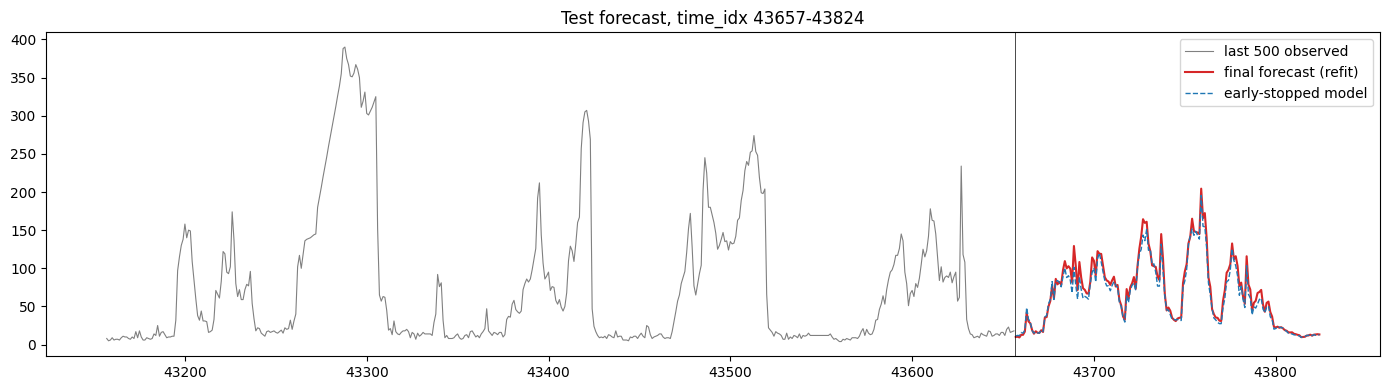

In [30]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(np.arange(T_full - 500, T_full) + 1, y_raw[-500:], color="grey", lw=0.8, label="last 500 observed")
ax.plot(np.arange(T_full, T_full + 168) + 1, pred, color="C3", lw=1.5, label="final forecast (refit)")
ax.plot(np.arange(T_full, T_full + 168) + 1, pred_es, "--", color="C0", lw=1, label="early-stopped model")
ax.axvline(T_full + 0.5, color="black", lw=0.5)
ax.set_title("Test forecast, time_idx 43657-43824"); ax.legend()
plt.tight_layout(); plt.show()

In [31]:
test_idx = np.arange(T_full + 1, T_full + 169)
assert test_idx[0] == 43657 and test_idx[-1] == 43824

pd.DataFrame({"time_idx": test_idx, "forecast": pred}).to_csv("submission_forecast.csv", index=False)

submission = ", ".join(f"{v:.4f}" for v in pred)

print(f"P = {P}, E = {E_total}")
print(f"first value (time_idx 43657): {pred[0]:.4f}, last value (time_idx 43824): {pred[-1]:.4f}")
print(f"\n values: {submission}")

P = 38868, E = 19
first value (time_idx 43657): 10.0318, last value (time_idx 43824): 13.2991

 values: 10.0318, 10.3198, 9.3895, 12.8958, 12.8295, 17.0446, 41.5978, 30.4400, 27.8706, 19.0788, 14.2809, 17.5004, 15.5062, 15.3794, 18.8541, 16.5557, 35.6130, 36.0639, 49.9611, 57.0811, 77.1584, 60.4318, 86.1683, 79.0079, 82.1599, 78.5554, 97.7896, 109.4439, 99.9324, 102.8090, 99.5321, 81.7112, 129.2398, 103.5139, 71.5355, 108.2501, 87.8403, 73.9216, 71.7020, 67.1124, 66.7904, 82.1619, 114.2669, 109.9160, 90.7153, 122.4907, 119.0917, 118.8575, 103.2627, 88.2094, 84.1080, 82.7171, 78.2964, 84.1541, 89.0082, 76.1471, 78.1646, 58.7339, 51.4272, 36.9578, 32.5632, 72.7743, 60.4259, 75.3356, 80.4611, 88.5653, 73.3301, 103.6732, 125.8600, 141.4993, 164.3721, 159.5199, 160.9642, 132.4931, 122.5564, 103.8486, 102.8492, 101.8197, 88.9408, 84.6542, 144.8732, 112.3815, 65.8874, 44.7401, 48.5643, 44.3318, 35.1655, 32.4710, 30.8369, 34.1298, 35.1988, 35.2751, 80.6156, 95.8753, 105.4332, 132.7139, 141.543